# Classificação de emoções de Ekman com rede neural em NumPy + TF-IDF

Classificador **multirrótulo** de mensagens em português nas **7 emoções de Ekman** (medo, tristeza, raiva, nojo,
surpresa, alegria e neutro), usando uma **rede neural implementada do zero em NumPy** (sem PyTorch/TensorFlow) sobre
features **TF-IDF**.

### Destaques

- Rede neural própria: forward, backpropagation, entropia cruzada binária com **peso por classe** e mini-batches.
- Entrada esparsa: TF-IDF de palavras + n-gramas de caracteres, reduzido a 5.000 features por **chi²**.
- *Early stopping* por ROC-AUC na validação e **limiar ajustado por classe**.
- Treino completo em **menos de 1 minuto em CPU**.
- Resultado no teste: **ROC-AUC macro 0,864** e **F1 macro 0,542**, empatando com uma regressão logística de referência.

### Dados

Versão em português do [GoEmotions](https://github.com/google-research/google-research/tree/master/goemotions).
As 27 emoções originais são agrupadas nas 7 de Ekman pelo mapeamento oficial do próprio GoEmotions:

| Ekman | Emoções do GoEmotions |
|---|---|
| medo | medo, nervosismo |
| tristeza | tristeza, luto, decepção, remorso, constrangimento |
| raiva | raiva, irritação, desaprovação |
| nojo | nojo |
| surpresa | surpresa, percepção, confusão, curiosidade |
| alegria | alegria, diversão, aprovação, empolgação, gratidão, amor, otimismo, alívio, orgulho, admiração, desejo, cuidado |
| neutro | neutro |

### Como executar

1. Gere `train.csv`, `validation.csv` e `test.csv` com o notebook de EDA (`eda_goemotions_ptbr.ipynb`).
2. Coloque os arquivos na pasta `data_processed/` (no Google Colab, o notebook pede o upload automaticamente).
3. Rode todas as células. Os hiperparâmetros ficam na célula de configuração.

### Sumário

1. Configuração · 2. Rede neural · 3. Dados e rótulos · 4. Features TF-IDF · 5. Treino · 6. Limiares por classe ·
7. Métricas no teste · 8. Referência: regressão logística · 9. Comparação final · 10. Conclusões

## 1. Configuração

In [1]:
import os
import copy
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score, hamming_loss,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
)

# ============================ Configuração ============================
DATA_DIR   = "data_processed"   # pasta com train.csv, validation.csv e test.csv
N_FEATURES = 5000               # features TF-IDF mantidas (as mais ligadas às emoções, por chi²)

HIDDEN     = [64]               # neurônios de cada camada oculta
ACTIVATION = "relu"             # 'sigmoid', 'relu' ou 'gelu'
LR         = 0.5                # taxa de aprendizado
EPOCHS     = 15
BATCH_SIZE = 64
SEED       = 42
# ======================================================================

# Estilo dos gráficos
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK2, GRID, SURF = "#52514e", "#e6e5e1", "#fcfcfb"
SEQ = sns.light_palette(PAL[0], as_cmap=True)
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "axes.prop_cycle": mpl.cycler(color=PAL),
})

In [2]:
# Se os CSVs não estiverem em DATA_DIR e o notebook estiver no Google Colab, pede o upload
need = ["train.csv", "validation.csv", "test.csv"]
if not all(os.path.exists(os.path.join(DATA_DIR, f)) for f in need):
    try:
        from google.colab import files
        os.makedirs(DATA_DIR, exist_ok=True)
        print("Envie train.csv, validation.csv e test.csv:")
        for name, content in files.upload().items():
            with open(os.path.join(DATA_DIR, os.path.basename(name)), "wb") as fh:
                fh.write(content)
    except ImportError:
        raise FileNotFoundError(f"Coloque {need} na pasta {DATA_DIR}/ (gerados pelo notebook de EDA)")

## 2. Rede neural em NumPy

Implementação própria de uma rede *feedforward* totalmente conectada:

- **Ativações:** sigmoide, ReLU ou GELU nas camadas ocultas; sigmoide na saída (uma probabilidade independente por emoção).
- **Inicialização:** Xavier/Glorot para sigmoide e He para ReLU/GELU.
- **Loss:** entropia cruzada binária, com **peso nos positivos** de cada classe para compensar o desbalanceamento.
- **Treino:** gradiente descendente com mini-batches. Matrizes esparsas são convertidas para densas só no lote atual.

In [3]:
class NeuralNetwork:
    """Rede neural feedforward para classificação multirrótulo.

    Parâmetros
    ----------
    dimension : lista com o nº de neurônios por camada, ex.: [5000, 64, 7]
    activation : ativação das camadas ocultas ('sigmoid', 'relu' ou 'gelu')
    """

    def __init__(self, dimension: list[int] = None, activation: str = 'sigmoid'):
        self.activation_name = activation.lower()
        self.historico = {}
        self.loss_curve_ = []
        self.pos_weight = None   # (n_saidas, 1); None = sem peso por classe

        self._funcoes_ativacao = {
            'sigmoid': self._sigmoide,
            'relu': self._relu,
            'gelu': self._gelu,
        }
        self._funcoes_derivadas = {
            'sigmoid': self._derivada_sigmoide,
            'relu': self._derivada_relu,
            'gelu': self._derivada_gelu,
        }

        if self.activation_name not in self._funcoes_ativacao:
            raise ValueError(
                f"Ativação '{activation}' não suportada. Escolha entre: 'sigmoid', 'relu', 'gelu'"
            )

        if dimension is not None:
            self.configurar_rede(dimension)
        else:
            self.dimension = None
            self.parametros = {}

    # ------------------------------------------------------------------
    # Inicialização da rede
    # ------------------------------------------------------------------
    def configurar_rede(self, dimension: list[int]):
        self.dimension = dimension
        self.parametros = {}
        for l in range(1, len(dimension)):
            n_in, n_out = dimension[l - 1], dimension[l]
            if self.activation_name == "sigmoid":
                fator = np.sqrt(2.0 / (n_in + n_out))   # Xavier/Glorot
            else:
                fator = np.sqrt(2.0 / n_in)             # He (ReLU/GELU)
            self.parametros['W' + str(l)] = np.random.randn(n_out, n_in) * fator
            self.parametros['b' + str(l)] = np.zeros((n_out, 1))

    # ------------------------------------------------------------------
    # Peso por classe: raiz(negativos / positivos), limitado a `maximo`
    # ------------------------------------------------------------------
    def definir_pesos(self, Y, maximo=30.0):
        """Y: (m, n_saidas) com 0/1."""
        pos = Y.sum(axis=0)
        neg = Y.shape[0] - pos
        w = np.sqrt(neg / np.maximum(pos, 1))
        self.pos_weight = np.clip(w, 1.0, maximo).reshape(-1, 1)

    # ------------------------------------------------------------------
    # Funções de ativação
    # ------------------------------------------------------------------
    def _sigmoide(self, z):
        z = np.clip(z, -500, 500)   # evita overflow no exp
        return 1 / (1 + np.exp(-z))

    def _relu(self, z):
        return np.maximum(0, z)

    def _gelu(self, z):
        return 0.5 * z * (1 + np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z**3)))

    # ------------------------------------------------------------------
    # Derivadas (recebem Z e A; cada uma usa o que precisa)
    # ------------------------------------------------------------------
    def _derivada_sigmoide(self, Z, A):
        return A * (1 - A)

    def _derivada_relu(self, Z, A):
        return (Z > 0).astype(float)

    def _derivada_gelu(self, Z, A):
        c = np.sqrt(2 / np.pi)
        t = np.tanh(c * (Z + 0.044715 * Z**3))
        dt = c * (1 + 3 * 0.044715 * Z**2)
        return 0.5 * (1 + t) + 0.5 * Z * (1 - t**2) * dt

    # ------------------------------------------------------------------
    # Forward
    # ------------------------------------------------------------------
    def forward(self, X):
        self.historico['A0'] = X
        A = X
        L = len(self.dimension)
        ativacao = self._funcoes_ativacao[self.activation_name]
        for l in range(1, L):
            Z = np.dot(self.parametros['W' + str(l)], A) + self.parametros['b' + str(l)]
            # camadas ocultas: ativação escolhida | saída: sempre sigmoide
            A = self._sigmoide(Z) if l == L - 1 else ativacao(Z)
            self.historico['Z' + str(l)] = Z
            self.historico['A' + str(l)] = A
        return A

    # ------------------------------------------------------------------
    # Backward
    # ------------------------------------------------------------------
    def backward(self, Y, taxa_aprendizado):
        L = len(self.dimension)
        m = Y.shape[1]
        derivada = self._funcoes_derivadas[self.activation_name]

        # Sigmoide + entropia cruzada binária => dZ = A - Y
        # Com peso nos positivos (w):           dZ = A(1 + (w-1)Y) - wY
        A_final = self.historico['A' + str(L - 1)]
        if self.pos_weight is None:
            dZ = A_final - Y
        else:
            w = self.pos_weight
            dZ = A_final * (1 + (w - 1) * Y) - w * Y

        for l in range(L - 1, 0, -1):
            A_anterior = self.historico['A' + str(l - 1)]
            dW = np.dot(dZ, A_anterior.T) / m
            db = np.sum(dZ, axis=1, keepdims=True) / m

            if l > 1:
                W_atual = self.parametros['W' + str(l)]   # usa W ANTES de atualizar
                Z_anterior = self.historico['Z' + str(l - 1)]
                dZ = np.dot(W_atual.T, dZ) * derivada(Z_anterior, A_anterior)

            self.parametros['W' + str(l)] -= taxa_aprendizado * dW
            self.parametros['b' + str(l)] -= taxa_aprendizado * db

    # ------------------------------------------------------------------
    # Loss (entropia cruzada binária, com peso opcional nos positivos)
    # ------------------------------------------------------------------
    def _loss(self, A, Y):
        A = np.clip(A, 1e-12, 1 - 1e-12)
        w = 1.0 if self.pos_weight is None else self.pos_weight
        return -np.mean(w * Y * np.log(A) + (1 - Y) * np.log(1 - A))

    # ------------------------------------------------------------------
    # Treino com mini-batches  ->  X: (m, features); y: vetor 0/1 ou (m, n_saidas)
    # ------------------------------------------------------------------
    def fit_batches(self, X, y, epocas=20, taxa_aprendizado=0.5, batch_size=64, verbose=True):
        y = np.asarray(y)
        if y.ndim == 1:
            y = y.reshape(-1, 1)
        m = X.shape[0]
        self.loss_curve_ = []
        for epoca in range(epocas):
            idx = np.random.permutation(m)
            perdas = []
            for i in range(0, m, batch_size):
                lote = idx[i:i + batch_size]
                Xb = self._lote_denso(X[lote])     # (features, batch)
                Yb = y[lote].T                     # (n_saidas, batch)
                A = self.forward(Xb)
                perdas.append(self._loss(A, Yb))
                self.backward(Yb, taxa_aprendizado)
            self.loss_curve_.append(float(np.mean(perdas)))
            if verbose:
                print(f"Época {epoca:3d} | loss = {self.loss_curve_[-1]:.4f}")
        return self

    @staticmethod
    def _lote_denso(Xb):
        if hasattr(Xb, "toarray"):
            Xb = Xb.toarray()
        return np.asarray(Xb).T

    # ------------------------------------------------------------------
    # Previsão
    # ------------------------------------------------------------------
    def predict_proba_batches(self, X, batch_size=2048):
        """X: (m, features). Retorna (m,) ou (m, n_saidas)."""
        probs = []
        for i in range(0, X.shape[0], batch_size):
            probs.append(self.forward(self._lote_denso(X[i:i + batch_size])).T)
        P = np.vstack(probs)
        return P.ravel() if P.shape[1] == 1 else P

    def predict_batches(self, X, limiar=0.5, batch_size=2048):
        """limiar: um número ou um valor por saída, ex.: [0.5, 0.3, ...]."""
        P = self.predict_proba_batches(X, batch_size)
        return (P >= np.asarray(limiar)).astype(int)

## 3. Dados e rótulos

In [4]:
EMOTIONS = ["admiration","amusement","anger","annoyance","approval","caring","confusion","curiosity","desire",
            "disappointment","disapproval","disgust","embarrassment","excitement","fear","gratitude","grief","joy",
            "love","nervousness","optimism","pride","realization","relief","remorse","sadness","surprise","neutral"]
# Ordem = prioridade para escolher a emoção principal quando há mais de uma (emoções negativas primeiro)
EKMAN = {
    "medo":     ["fear", "nervousness"],
    "tristeza": ["sadness", "grief", "disappointment", "remorse", "embarrassment"],
    "raiva":    ["anger", "annoyance", "disapproval"],
    "nojo":     ["disgust"],
    "surpresa": ["surprise", "realization", "confusion", "curiosity"],
    "alegria":  ["joy", "amusement", "approval", "excitement", "gratitude", "love", "optimism", "relief",
                 "pride", "admiration", "desire", "caring"],
    "neutro":   ["neutral"],
}
LABELS = list(EKMAN)
COLOR = dict(zip(LABELS, [PAL[4], PAL[2], PAL[1], PAL[5], PAL[3], PAL[0], PAL[6]]))

df = {s: pd.read_csv(os.path.join(DATA_DIR, f"{s}.csv")) for s in ["train", "validation", "test"]}
Y  = {s: np.stack([d[EKMAN[g]].max(axis=1).values for g in LABELS], axis=1) for s, d in df.items()}
# emoção principal: a primeira presente na ordem de prioridade acima
Y_single = {s: np.argmax(Y[s] == 1, axis=1) for s in Y}

resumo = pd.DataFrame({s: Y[s].sum(0) for s in Y}, index=LABELS)
resumo.loc["total de mensagens"] = [len(df[s]) for s in Y]
resumo

,train,validation,test
medo,721,105,97
tristeza,3251,389,378
raiva,5539,715,725
nojo,788,97,123
surpresa,5332,625,679
alegria,17100,2197,2074
neutro,12554,1569,1569
total de mensagens,42737,5377,5357


## 4. Features TF-IDF

1. **TF-IDF de palavras** (palavras soltas e pares de palavras) e **TF-IDF de caracteres** (pedaços de 2 a 5 letras).
   Tudo é ajustado **só no treino**.
2. **Seleção por chi²:** das ~100 mil features, ficam as `N_FEATURES` mais associadas a alguma das 7 emoções.
   Isso deixa a rede pequena e rápida e tira ruído.

A matriz é esparsa (quase tudo zero). A rede do grupo já lida com isso: `_lote_denso` converte só o lote atual.

In [5]:
t0 = time.time()
vec_word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)
vec_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, max_features=50000, sublinear_tf=True)
X_full = {"train": hstack([vec_word.fit_transform(df["train"]["text"]), vec_char.fit_transform(df["train"]["text"])]).tocsr()}
for s in ["validation", "test"]:
    X_full[s] = hstack([vec_word.transform(df[s]["text"]), vec_char.transform(df[s]["text"])]).tocsr()

chi = np.max([np.nan_to_num(chi2(X_full["train"], Y["train"][:, j])[0]) for j in range(len(LABELS))], axis=0)
idx = np.argsort(-chi)[:N_FEATURES]
X = {s: X_full[s][:, idx] for s in X_full}
feat_names = np.concatenate([vec_word.get_feature_names_out(), vec_char.get_feature_names_out()])[idx]

EMB = {"tfidf": {"X": X}}
print(f"TF-IDF completo: {X_full['train'].shape[1]:,} features -> {N_FEATURES:,} selecionadas | {time.time() - t0:.0f}s")
print("Exemplos de features selecionadas:", [f for f in feat_names[:200] if " " in f or len(f) > 4][:25])

TF-IDF completo: 100,000 features -> 5,000 selecionadas | 7s
Exemplos de features selecionadas: ['nojento', ' noj', ' medo', 'assustador', 'triste', 'com medo', 'medo de', 'ojent', 'nojen', 'medo ', ' noje', 'aterrorizante', 'jento', 'desculpa', 'sinto muito', '? ', ' med', 'sinto', 'valeu', 'edo ', 'horrível', 'obrigado', 'ssust', 'assus', 'susta']


## 5. Treino

- Arquitetura: `[N_FEATURES] + HIDDEN + [7]`, ativação `ACTIVATION` nas camadas ocultas e sigmoide na saída.
- Peso por classe com `definir_pesos` da própria rede (raiz de negativos/positivos), para compensar classes raras como medo e nojo.
- Treinamos uma época por vez e medimos a **validação** a cada época. Guardamos os pesos da época com maior **ROC-AUC
  macro na validação** (*early stopping*), porque a rede começa a decorar o treino depois de algumas épocas.

In [6]:
def treinar(X):
    np.random.seed(SEED)
    net = NeuralNetwork([X["train"].shape[1]] + HIDDEN + [len(LABELS)], activation=ACTIVATION)
    net.definir_pesos(Y["train"])
    hist, best = [], {"auc": -1}
    for ep in range(1, EPOCHS + 1):
        net.fit_batches(X["train"], Y["train"], epocas=1, taxa_aprendizado=LR, batch_size=BATCH_SIZE, verbose=False)
        Pv = net.predict_proba_batches(X["validation"])
        h = {"época": ep, "loss treino": net.loss_curve_[-1], "loss validação": net._loss(Pv.T, Y["validation"].T),
             "AUC validação": roc_auc_score(Y["validation"], Pv, average="macro")}
        hist.append(h)
        if h["AUC validação"] > best["auc"]:
            best = {"auc": h["AUC validação"], "época": ep, "parametros": copy.deepcopy(net.parametros)}
    net.parametros = best["parametros"]
    print(f"melhor época: {best['época']} | AUC validação = {best['auc']:.4f}")
    return net, pd.DataFrame(hist)

for name, e in EMB.items():
    print(f"\n### {name}")
    e["net"], e["hist"] = treinar(e["X"])


### tfidf


melhor época: 10 | AUC validação = 0.8575


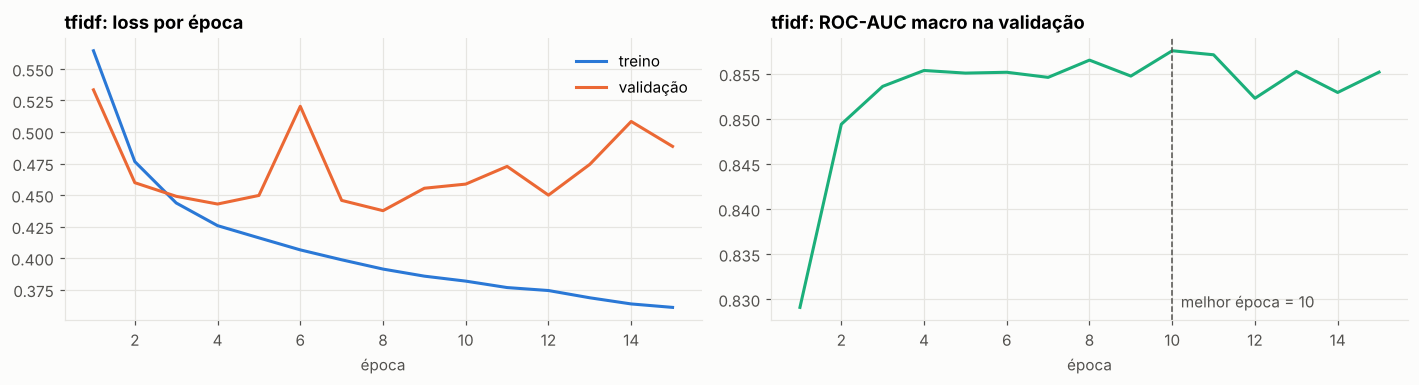

In [7]:
fig, axes = plt.subplots(len(EMB), 2, figsize=(13, 3.6 * len(EMB)), squeeze=False)
for row, (name, e) in zip(axes, EMB.items()):
    h = e["hist"]
    row[0].plot(h["época"], h["loss treino"], lw=2, label="treino")
    row[0].plot(h["época"], h["loss validação"], lw=2, label="validação")
    row[0].set_title(f"{name}: loss por época"); row[0].legend(frameon=False); row[0].set_xlabel("época")
    row[1].plot(h["época"], h["AUC validação"], lw=2, color=PAL[2])
    best_ep = h.loc[h["AUC validação"].idxmax(), "época"]
    row[1].axvline(best_ep, color=INK2, ls="--", lw=1); row[1].text(best_ep, h["AUC validação"].min(), f"  melhor época = {best_ep}", color=INK2)
    row[1].set_title(f"{name}: ROC-AUC macro na validação"); row[1].set_xlabel("época")
plt.tight_layout(); plt.show()

## 6. Limiares por classe

O limiar padrão de 0,5 não é o ideal para classes desbalanceadas. Para cada classe escolhemos, **na validação**, o limiar
que maximiza o F1. O `predict_batches` da rede já aceita um limiar por saída.

In [8]:
def melhores_limiares(Y_true, P):
    lim = []
    for j in range(Y_true.shape[1]):
        p, r, t = precision_recall_curve(Y_true[:, j], P[:, j])
        f1 = 2 * p * r / np.maximum(p + r, 1e-12)
        lim.append(float(t[np.argmax(f1[:-1])]))
    return np.array(lim)

for name, e in EMB.items():
    e["P"] = {s: e["net"].predict_proba_batches(e["X"][s]) for s in ["validation", "test"]}
    e["limiares"] = melhores_limiares(Y["validation"], e["P"]["validation"])
    print(name, dict(zip(LABELS, e["limiares"].round(3))))

tfidf {'medo': np.float64(0.716), 'tristeza': np.float64(0.49), 'raiva': np.float64(0.344), 'nojo': np.float64(0.787), 'surpresa': np.float64(0.369), 'alegria': np.float64(0.468), 'neutro': np.float64(0.386)}


## 7. Métricas no conjunto de teste

In [9]:
def metricas_multirrotulo(Y_true, P, lim):
    Yp = (P >= lim).astype(int)
    por_classe = pd.DataFrame({
        "precisão": precision_score(Y_true, Yp, average=None, zero_division=0),
        "recall":   recall_score(Y_true, Yp, average=None, zero_division=0),
        "F1":       f1_score(Y_true, Yp, average=None, zero_division=0),
        "ROC-AUC":  roc_auc_score(Y_true, P, average=None),
        "PR-AUC":   average_precision_score(Y_true, P, average=None),
        "suporte":  Y_true.sum(0),
    }, index=LABELS)
    geral = {
        "F1 micro": f1_score(Y_true, Yp, average="micro", zero_division=0),
        "F1 macro": f1_score(Y_true, Yp, average="macro", zero_division=0),
        "F1 ponderado": f1_score(Y_true, Yp, average="weighted", zero_division=0),
        "ROC-AUC macro": roc_auc_score(Y_true, P, average="macro"),
        "PR-AUC macro": average_precision_score(Y_true, P, average="macro"),
        "Hamming loss": hamming_loss(Y_true, Yp),
        "acerto exato (todas as classes)": accuracy_score(Y_true, Yp),
    }
    return por_classe, geral

RESULTADOS = {}
for name, e in EMB.items():
    pc, g = metricas_multirrotulo(Y["test"], e["P"]["test"], e["limiares"])
    pc05, g05 = metricas_multirrotulo(Y["test"], e["P"]["test"], 0.5)
    e["por_classe"], e["geral"] = pc, g
    RESULTADOS[name] = g
    print(f"\n### {name}: métricas por classe (limiares ajustados)")
    display(pc.round(3))
    display(pd.DataFrame({"limiar 0,5": g05, "limiares ajustados": g}).round(4))


### tfidf: métricas por classe (limiares ajustados)


,precisão,recall,F1,ROC-AUC,PR-AUC,suporte
medo,0.606,0.443,0.512,0.945,0.572,97
tristeza,0.519,0.476,0.497,0.861,0.505,378
raiva,0.369,0.572,0.448,0.817,0.467,725
nojo,0.469,0.374,0.416,0.918,0.443,123
surpresa,0.531,0.619,0.571,0.853,0.521,679
alegria,0.755,0.742,0.749,0.873,0.846,2074
neutro,0.475,0.816,0.601,0.783,0.550,1569


,"limiar 0,5",limiares ajustados
F1 micro,0.6104,0.6125
F1 macro,0.5460,0.5420
F1 ponderado,0.6115,0.6194
ROC-AUC macro,0.8643,0.8643
PR-AUC macro,0.5577,0.5577
Hamming loss,0.1194,0.1324
acerto exato (todas as classes),0.5079,0.4372


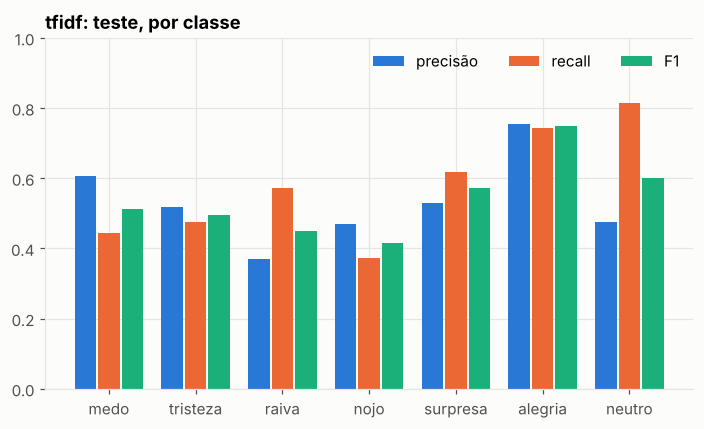

In [10]:
fig, axes = plt.subplots(1, len(EMB), figsize=(6.5 * len(EMB), 4), squeeze=False)
for ax, (name, e) in zip(axes[0], EMB.items()):
    pc = e["por_classe"]
    x = np.arange(len(LABELS)); w = 0.27
    for k, (m, c) in enumerate(zip(["precisão", "recall", "F1"], PAL[:3])):
        ax.bar(x + (k - 1) * w, pc[m], w * 0.92, color=c, label=m)
    ax.set_xticks(x, LABELS); ax.set_ylim(0, 1); ax.set_title(f"{name}: teste, por classe"); ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.show()

### 7.1 Visão de rótulo único

O chatbot precisa de **uma emoção principal** por mensagem. Testamos duas regras para escolher a emoção e ficamos com a que
tem maior F1 macro **na validação**:
- **maior probabilidade**: `argmax(P)`. Tende a favorecer alegria e neutro, que são as classes mais comuns;
- **probabilidade relativa ao limiar**: `argmax(P / limiar)`. Cada classe é comparada com o seu próprio limiar, o que
  compensa o desbalanceamento.

A previsão é comparada com a emoção principal do dataset (quando o comentário tem mais de uma, vale a ordem de prioridade: medo > tristeza > raiva > nojo >
surpresa > alegria > neutro).

tfidf | F1 macro na validação: {'maior probabilidade': 0.5201, 'relativa ao limiar': 0.5118} -> regra escolhida: maior probabilidade
tfidf {'acurácia': 0.5932, 'F1 macro': 0.5253, 'recall medo': 0.5155, 'recall tristeza': 0.4385}


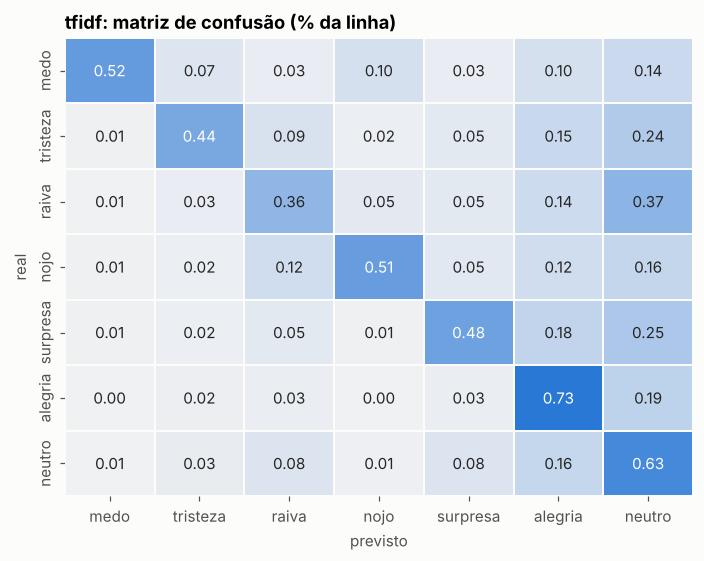

In [11]:
y_true_single = Y_single["test"]
REGRAS = {"maior probabilidade": lambda P, lim: P.argmax(1), "relativa ao limiar": lambda P, lim: (P / lim).argmax(1)}
for name, e in EMB.items():
    f1_val = {r: f1_score(Y_single["validation"], f(e["P"]["validation"], e["limiares"]), average="macro") for r, f in REGRAS.items()}
    e["regra"] = max(f1_val, key=f1_val.get)
    print(name, "| F1 macro na validação:", {r: round(v, 4) for r, v in f1_val.items()}, "-> regra escolhida:", e["regra"])
    y_pred = REGRAS[e["regra"]](e["P"]["test"], e["limiares"])
    e["single"] = {"acurácia": accuracy_score(y_true_single, y_pred),
                   "F1 macro": f1_score(y_true_single, y_pred, average="macro"),
                   "recall medo": recall_score(y_true_single == 0, y_pred == 0),
                   "recall tristeza": recall_score(y_true_single == 1, y_pred == 1)}
    print(name, {k: round(v, 4) for k, v in e["single"].items()})

fig, axes = plt.subplots(1, len(EMB), figsize=(6.5 * len(EMB), 5.2), squeeze=False)
for ax, (name, e) in zip(axes[0], EMB.items()):
    cm = confusion_matrix(y_true_single, REGRAS[e["regra"]](e["P"]["test"], e["limiares"]), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap=SEQ, xticklabels=LABELS, yticklabels=LABELS, cbar=False, ax=ax,
                linewidths=1, linecolor=SURF)
    ax.set_xlabel("previsto"); ax.set_ylabel("real"); ax.set_title(f"{name}: matriz de confusão (% da linha)"); ax.grid(False)
plt.tight_layout(); plt.show()

## 8. Referência: regressão logística nas mesmas features

Para saber se a camada oculta da rede ajuda, comparamos com um modelo linear simples (regressão logística, uma por
classe, com peso para classes raras) nas mesmas features.

In [12]:
for name, e in EMB.items():
    lr = OneVsRestClassifier(LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0), n_jobs=-1)
    lr.fit(e["X"]["train"], Y["train"])
    Pv, Pt = lr.predict_proba(e["X"]["validation"]), lr.predict_proba(e["X"]["test"])
    _, g = metricas_multirrotulo(Y["test"], Pt, melhores_limiares(Y["validation"], Pv))
    RESULTADOS[f"{name} + regressão logística"] = g

## 9. Comparação final

In [13]:
comp = pd.DataFrame(RESULTADOS).T
for name, e in EMB.items():
    comp.loc[name, "acurácia (rótulo único)"] = e["single"]["acurácia"]
comp.round(4)

,F1 micro,F1 macro,F1 ponderado,ROC-AUC macro,PR-AUC macro,Hamming loss,acerto exato (todas as classes),acurácia (rótulo único)
tfidf,0.6125,0.5420,0.6194,0.8643,0.5577,0.1324,0.4372,0.5932
tfidf + regressão logística,0.6086,0.5472,0.6169,0.8627,0.5452,0.1348,0.4275,NaN


## 10. Conclusões

**Resultados no conjunto de teste** (dados que a rede nunca viu):

| Métrica | Valor |
|---|---|
| F1 macro (limiares ajustados / limiar 0,5) | **0,542** / 0,546 |
| F1 micro (limiares ajustados) | 0,613 |
| ROC-AUC macro | **0,864** |
| Acurácia da emoção principal (7 classes) | **0,593** (o acaso daria ~0,14) |

**F1 por emoção:** alegria 0,75 · neutro 0,60 · surpresa 0,57 · medo 0,51 · tristeza 0,50 · raiva 0,45 · nojo 0,42

- **Medo e nojo têm poucos exemplos, mas ROC-AUC alta (0,95 e 0,92).** O modelo reconhece bem as palavras típicas
  ("nojento", "assustador", "com medo"); o F1 fica menor porque, com ~100 exemplos no teste, cada erro pesa muito.
- **O erro mais comum é mandar emoções para neutro:** 37% da raiva, 25% da surpresa e 24% da tristeza viram neutro.
- **Raiva e nojo se confundem:** 12% das mensagens de nojo são classificadas como raiva, o que é esperado para
  emoções tão próximas.
- **Limiar por classe:** ajustar o limiar na validação melhora um pouco o F1 micro e o ponderado, mas o F1 macro fica
  praticamente igual ao do limiar fixo de 0,5 (0,542 contra 0,546).
- Para escolher a emoção principal, a **maior probabilidade simples** foi melhor na validação (F1 macro 0,520 contra
  0,512 da regra relativa ao limiar) e foi a usada no teste.
- A **regressão logística** nas mesmas features empata com a rede (F1 macro 0,547 contra 0,542). Com TF-IDF, as
  features fazem a maior parte do trabalho.
- Em comparação com a versão de 6 categorias de bem-estar do projeto (F1 macro 0,580), o Ekman fica um pouco abaixo.
  A diferença vem principalmente de separar **nojo** de **raiva**: mais classes, F1 menor.

### Próximos passos

1. Ajustar `N_FEATURES` e `HIDDEN` na validação.
2. Usar a diferença entre as duas maiores probabilidades como medida de incerteza da previsão.
3. Acrescentar frases escritas originalmente em português para as classes com menos exemplos (medo e nojo).